# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

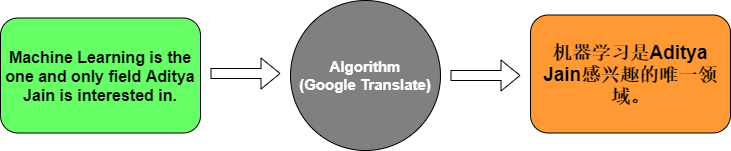

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
!pip install tensorflow

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.0000e+00 - loss: 2.4882

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.0000e+00 - loss: 2.4882 - val_accuracy: 0.0000e+00 - val_loss: 2.4874


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.1429 - loss: 2.4784

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.1429 - loss: 2.4784 - val_accuracy: 0.0000e+00 - val_loss: 2.4897


... (143 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.8571 - loss: 0.5149 - val_accuracy: 0.0000e+00 - val_loss: 5.7580


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 609ms/step - accuracy: 0.5714 - loss: 1.9720

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 630ms/step - accuracy: 0.5714 - loss: 1.9720


Test Accuracy: 0.5714285969734192


In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 343ms/step


Input: How are you?
Translation: comment va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**1. What does the Embedding layer do to a word index?**

A word index is just a number, like 5 for "hello". That number alone tells the model nothing about the word. The Embedding layer turns each number into a list of numbers (a vector, here 64 numbers long). The model learns these vectors during training, so words with similar meaning end up with similar vectors.

**2. What is the role of the Encoder LSTM?**

The Encoder LSTM reads the English sentence one word at a time and remembers what it has seen so far. At the end it gives one vector that sums up the meaning of the whole sentence. You can think of it as the part that "understands" the input.

**3. What does the Decoder LSTM do?**

The Decoder LSTM takes the summary from the encoder (copied for each output step by RepeatVector) and builds the French sentence step by step. At every step it produces an output that is used to pick the next French word.

**4. Why do we use softmax in the final layer?**

At each step the model has to choose one word from the whole French vocabulary. Softmax turns the raw scores into probabilities that add up to 1, so we get a chance for every word. We then pick the word with the highest chance. It also works with the sparse categorical crossentropy loss we use for training.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

Dataset size: (10000, 2)


English vocab: 4017 max length: 7
French vocab: 6512 max length: 10
Epoch 1/30


113/113 - 12s - 103ms/step - accuracy: 0.5293 - loss: 4.8311 - val_accuracy: 0.5270 - val_loss: 3.8253


Epoch 2/30


113/113 - 7s - 62ms/step - accuracy: 0.5340 - loss: 3.5997 - val_accuracy: 0.5270 - val_loss: 3.6201


Epoch 3/30


... (52 outputs left out)

113/113 - 10s - 84ms/step - accuracy: 0.6096 - loss: 2.4147 - val_accuracy: 0.5856 - val_loss: 3.1110


Epoch 30/30


113/113 - 11s - 100ms/step - accuracy: 0.6124 - loss: 2.3804 - val_accuracy: 0.5886 - val_loss: 3.0964


Test accuracy: 0.5977998971939087


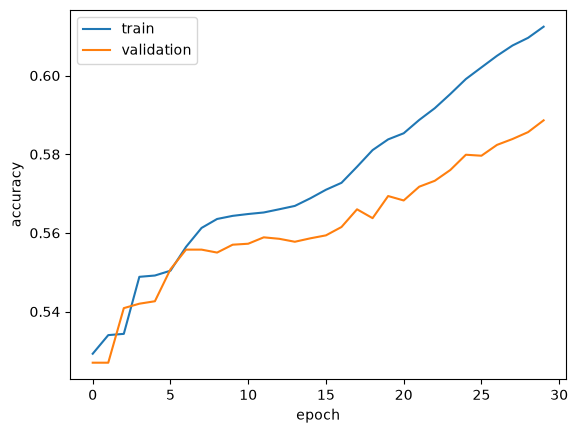

Hello. -> c'est
How are you? -> nous sommes nous


I love this product. -> j'aime un la
This shirt is too big. -> c'est est est


Thank you very much. -> j'aime le

English:   we had an appointment.
Real:      nous avions un rendez-vous.
Predicted: nous nous nous nous nous

English:   he came by car.
Real:      il est venu en voiture.


Predicted: il est est de

English:   we all cried a lot.
Real:      nous avons toutes beaucoup pleuré.
Predicted: nous nous nous à

English:   i had no luck yesterday.
Real:      je n'ai pas eu de chance hier.


Predicted: je ne pas pas de

English:   the house is warm.
Real:      il fait bon dans la maison.
Predicted: c'est est est est



In [8]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

df = pd.read_csv("eng_french_small.csv")
df.columns = ["english", "french"]
df["english"] = df["english"].str.lower()
df["french"] = df["french"].str.lower()
print("Dataset size:", df.shape)

eng_tok = Tokenizer()
eng_tok.fit_on_texts(df["english"])
eng_seq = eng_tok.texts_to_sequences(df["english"])

frn_tok = Tokenizer()
frn_tok.fit_on_texts(df["french"])
frn_seq = frn_tok.texts_to_sequences(df["french"])

eng_vocab = len(eng_tok.word_index) + 1
frn_vocab = len(frn_tok.word_index) + 1

eng_pad = pad_sequences(eng_seq, padding="post")
frn_pad = pad_sequences(frn_seq, padding="post")

print("English vocab:", eng_vocab, "max length:", eng_pad.shape[1])
print("French vocab:", frn_vocab, "max length:", frn_pad.shape[1])

X_train, X_test, y_train, y_test = train_test_split(eng_pad, frn_pad, test_size=0.2, random_state=42)

model2 = tf.keras.Sequential([
    tf.keras.Input(shape=(eng_pad.shape[1],)),
    tf.keras.layers.Embedding(input_dim=eng_vocab, output_dim=64, mask_zero=True),
    tf.keras.layers.LSTM(128),
    tf.keras.layers.RepeatVector(frn_pad.shape[1]),
    tf.keras.layers.LSTM(128, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation="softmax"))
])

model2.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history = model2.fit(
    X_train, np.expand_dims(y_train, -1),
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    verbose=2
)

loss, acc = model2.evaluate(X_test, np.expand_dims(y_test, -1), verbose=0)
print("Test accuracy:", acc)

plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.show()

def translate(sentence):
    seq = eng_tok.texts_to_sequences([sentence.lower()])
    seq = pad_sequences(seq, maxlen=eng_pad.shape[1], padding="post")
    pred = model2.predict(seq, verbose=0)
    ids = np.argmax(pred, axis=-1)[0]
    words = [frn_tok.index_word[i] for i in ids if i != 0]
    return " ".join(words)

for s in ["Hello.", "How are you?", "I love this product.", "This shirt is too big.", "Thank you very much."]:
    print(s, "->", translate(s))

print()
sample = df.sample(5, random_state=1)
for eng, frn in zip(sample["english"], sample["french"]):
    print("English:  ", eng)
    print("Real:     ", frn)
    print("Predicted:", translate(eng))
    print()